# Adult Census Income Classification

## Submission notebook

This notebook is the authoritative, reproducible implementation for the final classification assignment. It predicts whether recorded income is `<=50K` or `>50K` using the UCI Adult Census Income dataset and compares Scikit-Learn models with a TensorFlow/Keras neural network.

### Required assessment evidence
1. Dataset eligibility and data-quality decisions
2. Leakage-free preprocessing and reproducible splitting
3. At least seven distinct, traceable experiments
4. Traditional ML and TensorFlow/Keras deep learning using `tf.data`
5. Validation comparison using accuracy, precision, recall, F1-score, and ROC-AUC
6. Learning curves, TensorBoard curves, ROC curves, and confusion matrices
7. Interpretation, limitations, saved artifacts, and reload verification

The earlier exploratory work is preserved separately in `Income334_classifier_full_history.ipynb`; it is not part of this authoritative submission workflow.


## 1. Environment and reproducibility

The next cell imports all dependencies used by this notebook. Random seed `42` is applied in the authoritative modelling section. Install dependencies from `requirements.txt` and select the `Adult Income (Python 3.13)` kernel before running top to bottom.


### What: Import the tools

We load the libraries for data handling, preprocessing, modelling, plotting, and TensorFlow.

**Why:** Keeping imports together makes the notebook easier to reproduce.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Scikit-Learn Tools
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    roc_auc_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_class_weight

# Deep Learning Tools
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("Environment initialized and all libraries successfully imported!")

Environment initialized and all libraries successfully imported!


## Project objective

**What:** Predict whether recorded income is `<=50K` or `>50K`.

**Why:** This is a binary classification problem with mixed numerical and categorical data. We compare traditional ML with a neural network and explain the results.

**Dataset:** UCI Adult Census Income dataset. It is open, non-synthetic, and larger than the required 20,000 raw rows.


## 2. Dataset loading and eligibility

### Objective
Load the Adult Census Income Dataset into a pandas DataFrame so that we can inspect its structure and verify that the raw dataset meets the assignment's minimum requirement of 20,000 rows.

We will first load the original dataset without removing rows or changing column values.

### What: Find the project folder

The notebook uses files stored beside it.

**Why:** This works locally without a Google Drive mount or hidden path.

In [2]:
# The dataset is stored beside this notebook, so no Google Drive mount is needed.
DATA_PATH = os.path.dirname(os.path.abspath("Income334_classifier.ipynb"))

print("Dataset directory:", DATA_PATH)
print(os.listdir(DATA_PATH))

Dataset directory: C:\Users\frank\Downloads\Adult_dataset
['.gitignore', '.venv', '.vscode', 'adult.data', 'adult.names', 'adult.test', 'adult_income_classification.ipynb', 'artifacts', 'environment.txt', 'github_submission', 'google_drive_submission', 'Income classifier', 'Income334_classifier.ipynb', 'Income334_classifier_full_history.ipynb', 'Index', 'logs', 'old.adult.names', 'README.md', 'REPORT_DRAFT.md', 'requirements.txt', 'Untitled']


### What: Load the original data

We read the supplied training and test files without deleting rows.

**Why:** We first preserve the original data so the assignment dataset can be checked honestly.

In [3]:
DATA_PATH = os.path.dirname(os.path.abspath("Income334_classifier.ipynb"))

columns = [
    "age", "workclass", "fnlwgt", "education",
    "education_num", "marital_status", "occupation",
    "relationship", "race", "sex", "capital_gain",
    "capital_loss", "hours_per_week", "native_country",
    "income"
]

train_df = pd.read_csv(
    os.path.join(DATA_PATH, "adult.data"),
    header=None,
    names=columns,
    skipinitialspace=True
)

test_df = pd.read_csv(
    os.path.join(DATA_PATH, "adult.test"),
    header=None,
    names=columns,
    skiprows=1,
    skipinitialspace=True
)

print("Loaded local Adult dataset files.")

Loaded local Adult dataset files.


### What: Check dataset size

We count the training rows, test rows, and total raw rows.

**Why:** The assignment requires at least 20,000 raw records.

In [4]:
print("Training set shape:", train_df.shape)
print("Test set shape:", test_df.shape)
print("Total raw rows:", len(train_df) + len(test_df))

display(train_df.head())

Training set shape: (32561, 15)
Test set shape: (16281, 15)
Total raw rows: 48842


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


### What: Check the target balance

We count both income classes.

**Why:** Class imbalance affects metric choice and may make accuracy misleading.

In [5]:
print("Income class counts:")
print(train_df["income"].value_counts())

print("\nIncome class percentages:")
print(
    (train_df["income"].value_counts(normalize=True) * 100).round(2)
)

Income class counts:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Income class percentages:
income
<=50K    75.92
>50K     24.08
Name: proportion, dtype: float64


### What: Find missing-value markers

We look for normal nulls and question-mark values.

**Why:** Missing values must be handled before models can use the data.

In [6]:
print("Missing values (standard nulls):")
print(train_df.isnull().sum())

print("\nValues marked with '?':")
print(
    train_df.astype("string")
    .apply(lambda column: column.str.strip().eq("?").sum())
    .loc[lambda counts: counts > 0]
)

Missing values (standard nulls):
age               0
workclass         0
fnlwgt            0
education         0
education_num     0
marital_status    0
occupation        0
relationship      0
race              0
sex               0
capital_gain      0
capital_loss      0
hours_per_week    0
native_country    0
income            0
dtype: int64

Values marked with '?':


workclass         1836
occupation        1843
native_country     583
dtype: int64


### What: Count exact duplicates

We check whether complete rows are repeated.

**Why:** The decision to keep or remove duplicates should be visible and justified.

In [7]:
duplicate_count = train_df.duplicated().sum()

print("Exact duplicate rows in training data:", duplicate_count)

Exact duplicate rows in training data: 24


### What: Separate feature types

We identify numerical and categorical columns.

**Why:** Numerical columns need scaling; categorical columns need encoding.

In [8]:
print("Dataset column data types:")
print(train_df.dtypes)

numerical_features = train_df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = train_df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("\nNumerical columns:", numerical_features)
print("\nCategorical columns:", categorical_features)

Dataset column data types:
age               int64
workclass           str
fnlwgt            int64
education           str
education_num     int64
marital_status      str
occupation          str
relationship        str
race                str
sex                 str
capital_gain      int64
capital_loss      int64
hours_per_week    int64
native_country      str
income              str
dtype: object

Numerical columns: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Categorical columns: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country', 'income']


C:\Users\frank\AppData\Local\Temp\ipykernel_9620\2013972183.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = train_df.select_dtypes(


### What: Review numerical features

We inspect summary statistics for age, hours, capital values, and other numeric fields.

**Why:** This helps identify scale differences and unusual values before preprocessing.

In [9]:
numerical_features = [
    "age",
    "fnlwgt",
    "education_num",
    "capital_gain",
    "capital_loss",
    "hours_per_week",
]

train_df[numerical_features].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,32561.0,38.58,13.64,17.0,28.0,37.0,48.0,90.0
fnlwgt,32561.0,189778.37,105549.98,12285.0,117827.0,178356.0,237051.0,1484705.0
education_num,32561.0,10.08,2.57,1.0,9.0,10.0,12.0,16.0
capital_gain,32561.0,1077.65,7385.29,0.0,0.0,0.0,0.0,99999.0
capital_loss,32561.0,87.30,402.96,0.0,0.0,0.0,0.0,4356.0
hours_per_week,32561.0,40.44,12.35,1.0,40.0,40.0,45.0,99.0


### Data-quality decisions

Question marks are converted to missing values. Categorical missing values are imputed as `Unknown`, and numerical values use a median learned only from the fitting split. The 24 exact duplicate training rows are retained because the supplied benchmark is evaluated as provided; the count is reported rather than silently changing the sample distribution.


### What: Standardise missing values

Question marks become proper missing values.

**Why:** The preprocessing pipeline can then apply one consistent imputation rule.

In [10]:
train_clean = train_df.copy()
test_clean = test_df.copy()

train_clean.replace(r"^\s*\?\s*$", np.nan, regex=True, inplace=True)
test_clean.replace(r"^\s*\?\s*$", np.nan, regex=True, inplace=True)

print("Missing values in training data:")
print(train_clean.isnull().sum().loc[lambda x: x > 0])

print("\nMissing values in test data:")
print(test_clean.isnull().sum().loc[lambda x: x > 0])

Missing values in training data:
workclass         1836
occupation        1843
native_country     583
dtype: int64

Missing values in test data:
workclass         963
occupation        966
native_country    274
dtype: int64


### What: Separate inputs and labels

`X` contains the predictor columns and `y` contains the income label.

**Why:** The target must not be used as an input feature.

In [11]:
X_train = train_clean.drop(columns=["income"])
y_train = train_clean["income"]

X_test = test_clean.drop(columns=["income"])
y_test = test_clean["income"]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target classes:")
print(y_train.value_counts())

print("\nTest target classes:")
print(y_test.value_counts())

X_train shape: (32561, 14)
y_train shape: (32561,)
X_test shape: (16281, 14)
y_test shape: (16281,)

Training target classes:
income
<=50K    24720
>50K      7841
Name: count, dtype: int64

Test target classes:
income
<=50K.    12435
>50K.      3846
Name: count, dtype: int64


### What: Standardise target labels

We remove spaces and the trailing period used in the test file.

**Why:** Both files must use exactly the same two class labels.

In [12]:
y_train = y_train.str.strip().str.rstrip(".")
y_test = y_test.str.strip().str.rstrip(".")

print("Training classes:", sorted(y_train.unique()))
print("Test classes:", sorted(y_test.unique()))

print("\nTest target counts:")
print(y_test.value_counts())

Training classes: ['<=50K', '>50K']
Test classes: ['<=50K', '>50K']

Test target counts:
income
<=50K    12435
>50K      3846
Name: count, dtype: int64


### What: Confirm final feature groups

We create the numerical and categorical feature lists used by the preprocessor.

**Why:** Explicit column lists keep the feature mapping stable for every model.

In [13]:
numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:", numerical_features)
print("\nNumber of numerical features:", len(numerical_features))

print("\nCategorical features:", categorical_features)
print("Number of categorical features:", len(categorical_features))

Numerical features: ['age', 'fnlwgt', 'education_num', 'capital_gain', 'capital_loss', 'hours_per_week']

Number of numerical features: 6

Categorical features: ['workclass', 'education', 'marital_status', 'occupation', 'relationship', 'race', 'sex', 'native_country']
Number of categorical features: 8


C:\Users\frank\AppData\Local\Temp\ipykernel_9620\413146121.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X_train.select_dtypes(


## 3. Leakage-free preprocessing

**Objective:** Create separate preprocessing steps for numerical and categorical features, fitting them later on training data only.

### What: Build one preprocessing plan

Numerical values are median-imputed and scaled. Categorical values are filled with `Unknown` and one-hot encoded.

**Why:** The same transformation must be reused for every model to prevent inconsistent features.

In [14]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Improvement: Replace simple imputer with constant fillvalue 'Unknown'
# to preserve the predictive signal of missing information in census data.
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print("Refined preprocessing pipeline created successfully.")

Refined preprocessing pipeline created successfully.


## 4. Authoritative experiments and model selection

All models below use the same stratified 80/20 fitting/validation split. The preprocessor is fitted only on the fitting subset and then reused unchanged for validation and the official test transformation. The official test set is not used for model selection. F1-score for the `>50K` class is the primary selection metric because the positive class is the minority class.


### What: Create the leakage-free split

The official training data is split into fitting and validation sets using stratification and seed 42. The preprocessor is fitted only on the fitting rows.

**Why:** Validation and test information must not influence preprocessing or model selection.

In [15]:
from pathlib import Path
from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay
)
import joblib

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

X_fit_authoritative, X_val_authoritative, y_fit_authoritative, y_val_authoritative = train_test_split(
    X_train, y_train, test_size=0.20, random_state=SEED, stratify=y_train
)
authoritative_preprocessor = clone(preprocessor)
X_fit_processed_authoritative = authoritative_preprocessor.fit_transform(X_fit_authoritative)
X_val_processed_authoritative = authoritative_preprocessor.transform(X_val_authoritative)
X_test_processed_authoritative = authoritative_preprocessor.transform(X_test)

def dense_float(matrix):
    return matrix.toarray().astype("float32") if hasattr(matrix, "toarray") else np.asarray(matrix, dtype="float32")
X_fit_dense_authoritative = dense_float(X_fit_processed_authoritative)
X_val_dense_authoritative = dense_float(X_val_processed_authoritative)
X_test_dense_authoritative = dense_float(X_test_processed_authoritative)
y_fit_binary = (y_fit_authoritative == ">50K").astype("int32").to_numpy()
y_val_binary = (y_val_authoritative == ">50K").astype("int32").to_numpy()
y_test_binary = (y_test == ">50K").astype("int32").to_numpy()
print("Authoritative split:", X_fit_authoritative.shape, X_val_authoritative.shape)
print("Shared processed feature count:", X_fit_dense_authoritative.shape[1])

Authoritative split: (26048, 14) (6513, 14)
Shared processed feature count: 108


### What: Run the traditional experiments

We train seven distinct configurations and calculate all required metrics from validation predictions.

**Why:** Different algorithms and hyperparameters show systematic experimentation rather than repeated runs.

In [16]:
def metric_row(name, y_true, y_pred, y_score, split="validation"):
    return {"experiment": name, "split": split, "accuracy": accuracy_score(y_true, y_pred), "precision_>50K": precision_score(y_true, y_pred, zero_division=0), "recall_>50K": recall_score(y_true, y_pred, zero_division=0), "f1_>50K": f1_score(y_true, y_pred, zero_division=0), "roc_auc": roc_auc_score(y_true, y_score)}

traditional_experiments = {
    "Logistic Regression | balanced | C=0.1": LogisticRegression(C=0.1, max_iter=1000, class_weight="balanced", random_state=SEED),
    "Logistic Regression | balanced | C=1.0": LogisticRegression(C=1.0, max_iter=1000, class_weight="balanced", random_state=SEED),
    "Random Forest | balanced | 200 trees": RandomForestClassifier(n_estimators=200, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Random Forest | balanced | min_leaf=2": RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced", random_state=SEED, n_jobs=-1),
    "Gradient Boosting | 100 trees | lr=0.10": GradientBoostingClassifier(n_estimators=100, learning_rate=0.10, max_depth=3, random_state=SEED),
    "Gradient Boosting | 200 trees | lr=0.05": GradientBoostingClassifier(n_estimators=200, learning_rate=0.05, max_depth=3, random_state=SEED),
    "Gradient Boosting | 300 trees | lr=0.05 | depth=2": GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=2, random_state=SEED),
}
fitted_traditional_models = {}
validation_rows = []
for name, model in traditional_experiments.items():
    model.fit(X_fit_processed_authoritative, y_fit_authoritative)
    val_pred = model.predict(X_val_processed_authoritative)
    val_score = model.predict_proba(X_val_processed_authoritative)[:, 1]
    fitted_traditional_models[name] = model
    validation_rows.append(metric_row(name, y_val_binary, (val_pred == ">50K").astype("int32"), val_score))
validation_results_authoritative = pd.DataFrame(validation_rows).sort_values("f1_>50K", ascending=False).reset_index(drop=True)
display(validation_results_authoritative.style.format({c: "{:.4f}" for c in validation_results_authoritative.columns if c not in ["experiment", "split"]}))

,experiment,split,accuracy,precision_>50K,recall_>50K,f1_>50K,roc_auc
0,Random Forest | balanced | 200 trees,validation,0.8465,0.6562,0.7608,0.7047,0.9082
1,Random Forest | balanced | min_leaf=2,validation,0.8253,0.5950,0.8584,0.7029,0.9187
2,Gradient Boosting | 100 trees | lr=0.10,validation,0.8690,0.7881,0.6237,0.6963,0.9238
3,Gradient Boosting | 200 trees | lr=0.05,validation,0.8700,0.7952,0.6193,0.6963,0.9249
4,Logistic Regression | balanced | C=0.1,validation,0.8128,0.5751,0.8527,0.6869,0.9098
5,Logistic Regression | balanced | C=1.0,validation,0.8124,0.5743,0.8527,0.6863,0.9094
6,Gradient Boosting | 300 trees | lr=0.05 | depth=2,validation,0.8657,0.7880,0.6046,0.6842,0.9214


### What: Train the neural network

The network uses two dense layers, dropout, class weights, early stopping, and a TensorFlow `tf.data` input pipeline.

**Why:** This satisfies the deep-learning requirement and gives a fair comparison using the same processed features.

In [17]:
experiment_name_nn = "Neural Network | 64-32 dropout | Adam 0.001"
log_dir_authoritative = Path(DATA_PATH) / "logs" / "adult_income_nn" / "authoritative_64_32_dropout"
log_dir_authoritative.mkdir(parents=True, exist_ok=True)

train_dataset_authoritative = (
    tf.data.Dataset.from_tensor_slices((X_fit_dense_authoritative, y_fit_binary))
    .shuffle(len(X_fit_dense_authoritative), seed=SEED, reshuffle_each_iteration=True)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)
validation_dataset_authoritative = (
    tf.data.Dataset.from_tensor_slices((X_val_dense_authoritative, y_val_binary))
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)
test_dataset_authoritative = (
    tf.data.Dataset.from_tensor_slices((X_test_dense_authoritative, y_test_binary))
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

nn_authoritative = keras.Sequential([
    keras.Input(shape=(X_fit_dense_authoritative.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.30),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.20),
    layers.Dense(1, activation="sigmoid"),
], name="adult_income_nn_authoritative")
nn_authoritative.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")],
)
class_weights_authoritative = dict(enumerate(compute_class_weight(
    class_weight="balanced", classes=np.array([0, 1]), y=y_fit_binary
)))
history_authoritative = nn_authoritative.fit(
    train_dataset_authoritative,
    validation_data=validation_dataset_authoritative,
    epochs=30,
    class_weight=class_weights_authoritative,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
        keras.callbacks.TensorBoard(log_dir=str(log_dir_authoritative), histogram_freq=1),
    ],
    verbose=0,
)
nn_val_score = nn_authoritative.predict(validation_dataset_authoritative, verbose=0).ravel()
nn_val_pred = (nn_val_score >= 0.5).astype("int32")
validation_rows.append(metric_row(experiment_name_nn, y_val_binary, nn_val_pred, nn_val_score))
validation_results_authoritative = pd.DataFrame(validation_rows).sort_values("f1_>50K", ascending=False).reset_index(drop=True)
display(validation_results_authoritative.style.format({c: "{:.4f}" for c in validation_results_authoritative.columns if c not in ["experiment", "split"]}))

C:\Users\frank\Downloads\Adult_dataset\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


,experiment,split,accuracy,precision_>50K,recall_>50K,f1_>50K,roc_auc
0,Random Forest | balanced | 200 trees,validation,0.8465,0.6562,0.7608,0.7047,0.9082
1,Random Forest | balanced | min_leaf=2,validation,0.8253,0.5950,0.8584,0.7029,0.9187
2,Gradient Boosting | 100 trees | lr=0.10,validation,0.8690,0.7881,0.6237,0.6963,0.9238
3,Gradient Boosting | 200 trees | lr=0.05,validation,0.8700,0.7952,0.6193,0.6963,0.9249
4,Neural Network | 64-32 dropout | Adam 0.001,validation,0.8150,0.5778,0.8597,0.6911,0.9156
5,Logistic Regression | balanced | C=0.1,validation,0.8128,0.5751,0.8527,0.6869,0.9098
6,Logistic Regression | balanced | C=1.0,validation,0.8124,0.5743,0.8527,0.6863,0.9094
7,Gradient Boosting | 300 trees | lr=0.05 | depth=2,validation,0.8657,0.7880,0.6046,0.6842,0.9214


## 5. TensorBoard evidence for the neural-network experiment

The next cell displays the TensorBoard run inside the notebook. It is connected to the same log directory used during training, so the curves are traceable to the reported neural-network experiment.

### What: Display TensorBoard evidence

We read the event files created by the same neural-network run and plot loss, accuracy, and ROC-AUC.

**Why:** The curves prove which experiment produced the neural-network training history.

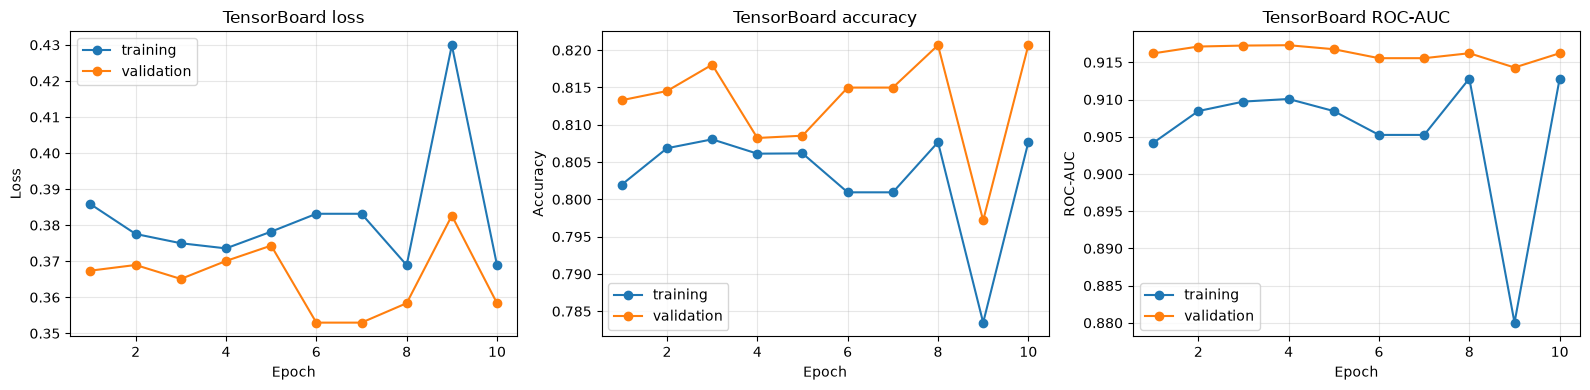

TensorBoard scalar curves rendered inline from: C:\Users\frank\Downloads\Adult_dataset\logs\adult_income_nn\authoritative_64_32_dropout


In [18]:
# Inline TensorBoard scalar visualisation for VS Code and exported notebooks.
# Keras 3 stores these metrics as tensor summaries rather than legacy scalar summaries.
from tensorboard.backend.event_processing import event_accumulator

FIGURE_DIR = Path(DATA_PATH) / "artifacts" / "report_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
from tensorflow.python.framework import tensor_util

def read_tensorboard_metric(split, tag):
    accumulator = event_accumulator.EventAccumulator(
        str(log_dir_authoritative / split)
    )
    accumulator.Reload()
    events = accumulator.Tensors(tag)
    values = [
        float(tensor_util.MakeNdarray(event.tensor_proto).reshape(-1)[0])
        for event in events
    ]
    return values

tensorboard_history = {
    "train_loss": read_tensorboard_metric("train", "epoch_loss"),
    "validation_loss": read_tensorboard_metric("validation", "epoch_loss"),
    "train_accuracy": read_tensorboard_metric("train", "epoch_accuracy"),
    "validation_accuracy": read_tensorboard_metric("validation", "epoch_accuracy"),
    "train_auc": read_tensorboard_metric("train", "epoch_auc"),
    "validation_auc": read_tensorboard_metric("validation", "epoch_auc"),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for train_key, validation_key, title, ylabel in [
    ("train_loss", "validation_loss", "TensorBoard loss", "Loss"),
    ("train_accuracy", "validation_accuracy", "TensorBoard accuracy", "Accuracy"),
    ("train_auc", "validation_auc", "TensorBoard ROC-AUC", "ROC-AUC"),
]:
    epochs = range(1, len(tensorboard_history[train_key]) + 1)
    axes[list(["TensorBoard loss", "TensorBoard accuracy", "TensorBoard ROC-AUC"]).index(title)].plot(
        epochs, tensorboard_history[train_key], marker="o", label="training"
    )
    axes[list(["TensorBoard loss", "TensorBoard accuracy", "TensorBoard ROC-AUC"]).index(title)].plot(
        epochs, tensorboard_history[validation_key], marker="o", label="validation"
    )

for axis, title, ylabel in zip(
    axes,
    ["TensorBoard loss", "TensorBoard accuracy", "TensorBoard ROC-AUC"],
    ["Loss", "Accuracy", "ROC-AUC"],
):
    axis.set(title=title, xlabel="Epoch", ylabel=ylabel)
    axis.grid(alpha=0.3)
    axis.legend()

fig.tight_layout()
fig.savefig(FIGURE_DIR / "tensorboard_scalar_curves.png", dpi=180, bbox_inches="tight")
plt.show()
print("TensorBoard scalar curves rendered inline from:", log_dir_authoritative)

## What counts as a distinct experiment

The authoritative table contains seven traditional configurations that differ in a declared model family or hyperparameter, plus one neural-network configuration. Re-running an identical configuration or evaluating it on another split does not count as a new experiment. The validation set is used for selection; the official test set is not used until the final evaluation below.

### What: Create required visual evidence

We plot validation ROC curves, the selected confusion matrix, and neural-network learning curves.

**Why:** These visuals support error analysis and explain model behaviour beyond one score.

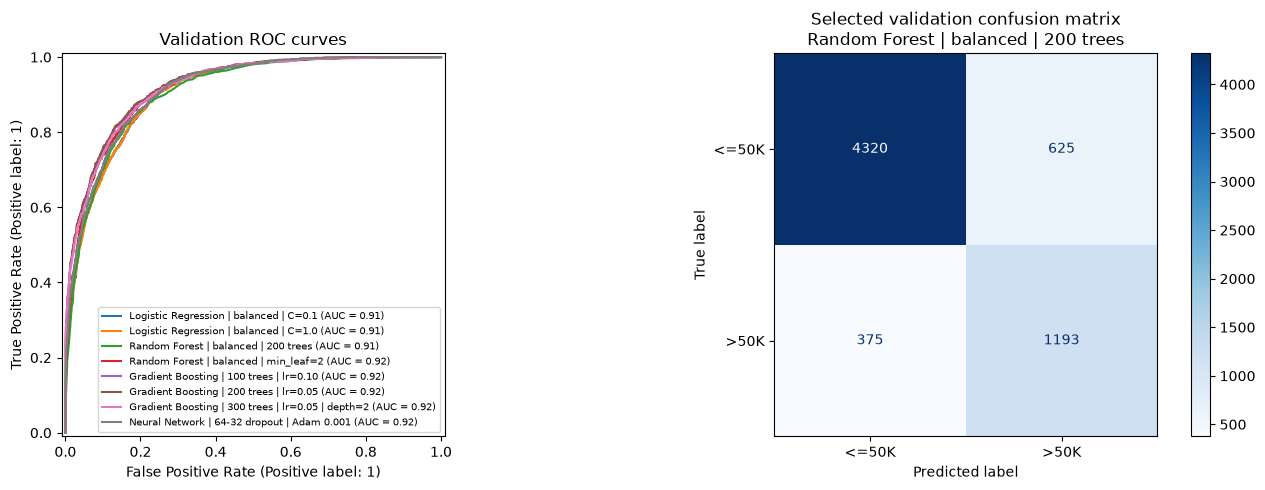

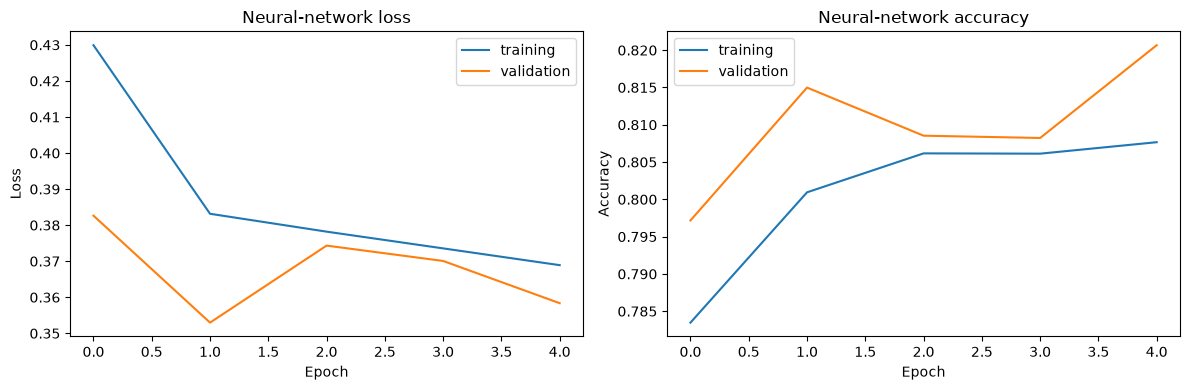

In [19]:
FIGURE_DIR = Path(DATA_PATH) / "artifacts" / "report_figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, model in fitted_traditional_models.items():
    score = model.predict_proba(X_val_processed_authoritative)[:, 1]
    RocCurveDisplay.from_predictions(y_val_binary, score, name=name, ax=axes[0])
RocCurveDisplay.from_predictions(y_val_binary, nn_val_score, name=experiment_name_nn, ax=axes[0])
axes[0].set_title("Validation ROC curves")
axes[0].legend(fontsize=7)
selected_name = validation_results_authoritative.iloc[0]["experiment"]
selected_val_pred = nn_val_pred if selected_name == experiment_name_nn else (fitted_traditional_models[selected_name].predict(X_val_processed_authoritative) == ">50K").astype("int32")
ConfusionMatrixDisplay.from_predictions(y_val_binary, selected_val_pred, display_labels=["<=50K", ">50K"], cmap="Blues", ax=axes[1])
axes[1].set_title(f"Selected validation confusion matrix\n{selected_name}")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "validation_roc_and_confusion_matrix.png", dpi=180, bbox_inches="tight")
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_authoritative.history["loss"], label="training")
axes[0].plot(history_authoritative.history["val_loss"], label="validation")
axes[0].set(title="Neural-network loss", xlabel="Epoch", ylabel="Loss")
axes[0].legend()
axes[1].plot(history_authoritative.history["accuracy"], label="training")
axes[1].plot(history_authoritative.history["val_accuracy"], label="validation")
axes[1].set(title="Neural-network accuracy", xlabel="Epoch", ylabel="Accuracy")
axes[1].legend()
fig.tight_layout()
fig.savefig(FIGURE_DIR / "neural_network_learning_curves.png", dpi=180, bbox_inches="tight")
plt.show()

### What: Evaluate once on the official test set

We select the model using validation F1-score, then refit the selected traditional pipeline on all official training rows and evaluate on the untouched test set.

**Why:** The test set estimates final generalisation and is not used for tuning.

,experiment,split,accuracy,precision_>50K,recall_>50K,f1_>50K,roc_auc
0,Random Forest | balanced | 200 trees,official_test_after_selection,0.8404,0.6419,0.7332,0.6845,0.9016


              precision    recall  f1-score   support

       <=50K       0.91      0.87      0.89     12435
        >50K       0.64      0.73      0.68      3846

    accuracy                           0.84     16281
   macro avg       0.78      0.80      0.79     16281
weighted avg       0.85      0.84      0.84     16281



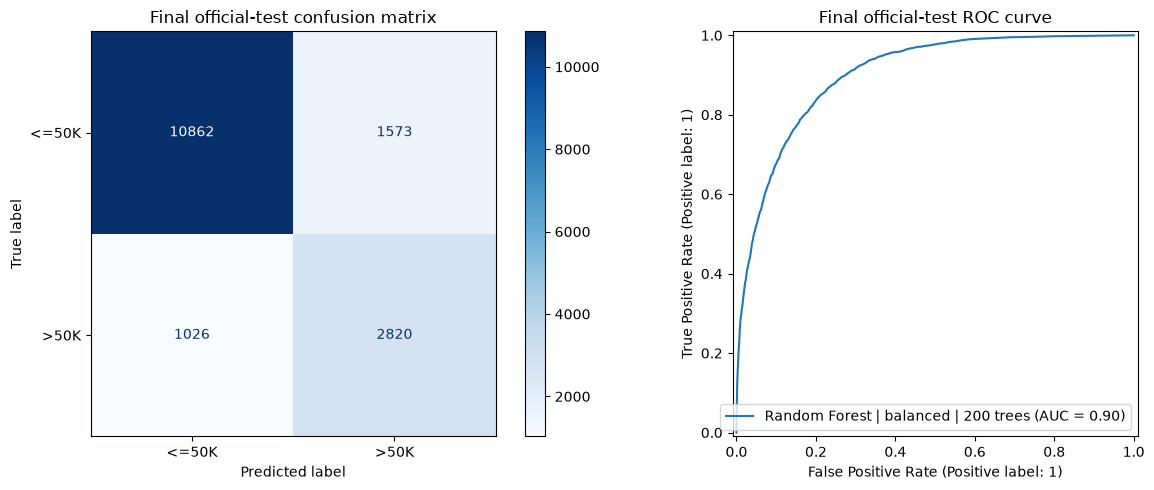

In [20]:
if selected_name == experiment_name_nn:
    final_test_score = nn_authoritative.predict(X_test_dense_authoritative, verbose=0).ravel()
    final_test_pred = (final_test_score >= 0.5).astype("int32")
    selected_traditional_pipeline = None
else:
    selected_model = fitted_traditional_models[selected_name]
    # After validation selection, refit once on all official training rows.
    # This creates the final deployable pipeline without using test labels.
    final_preprocessor = clone(preprocessor)
    selected_traditional_pipeline = Pipeline([("preprocessor", final_preprocessor), ("model", clone(selected_model))])
    selected_traditional_pipeline.fit(X_train, y_train)
    final_test_score = selected_traditional_pipeline.predict_proba(X_test)[:, 1]
    final_test_pred = (selected_traditional_pipeline.predict(X_test) == ">50K").astype("int32")
final_results = pd.DataFrame([metric_row(selected_name, y_test_binary, final_test_pred, final_test_score, split="official_test_after_selection")])
display(final_results.style.format({c: "{:.4f}" for c in final_results.columns if c not in ["experiment", "split"]}))
print(classification_report(y_test_binary, final_test_pred, target_names=["<=50K", ">50K"], zero_division=0))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay.from_predictions(y_test_binary, final_test_pred, display_labels=["<=50K", ">50K"], cmap="Blues", ax=axes[0])
axes[0].set_title("Final official-test confusion matrix")
RocCurveDisplay.from_predictions(y_test_binary, final_test_score, name=selected_name, ax=axes[1])
axes[1].set_title("Final official-test ROC curve")
plt.tight_layout()
plt.show()

## Data-quality record and saved artifacts

The exact duplicate count and missing-value policy are recorded below. The split-fitted preprocessor is saved for reproducibility. The selected traditional artifact is a complete final pipeline whose preprocessor is refitted on all official training rows only after validation-based model selection. The neural-network model uses the authoritative split-fitted feature mapping.


### What: Save the evidence and models

We record the duplicate decision, save result tables, and save both model types with their required preprocessing.

**Why:** Another person must be able to inspect and reuse the final artifacts.

In [21]:
duplicate_count_authoritative = train_df.duplicated().sum()
print(f"Exact duplicate rows retained from the supplied training file: {duplicate_count_authoritative}")
print("Missing-value policy: '?' -> NaN; categorical values -> 'Unknown'; numerical values -> median learned on the fitting split.")
ARTIFACT_DIR = Path(DATA_PATH) / "artifacts"
ARTIFACT_DIR.mkdir(exist_ok=True)
joblib.dump(authoritative_preprocessor, ARTIFACT_DIR / "adult_income_preprocessor_fit_split.joblib")
if selected_traditional_pipeline is not None:
    joblib.dump(selected_traditional_pipeline, ARTIFACT_DIR / "adult_income_selected_traditional_pipeline.joblib")
nn_authoritative.save(ARTIFACT_DIR / "adult_income_neural_network.keras")
experiment_metadata = pd.DataFrame([
    {"experiment": name, "model_family": "traditional", "hyperparameters": str(model.get_params()), "fit_rows": len(X_fit_authoritative), "validation_rows": len(X_val_authoritative), "preprocessor": "authoritative_preprocessor_v1", "tensorboard_log_dir": "not_applicable"}
    for name, model in traditional_experiments.items()
] + [{"experiment": experiment_name_nn, "model_family": "tensorflow_keras", "hyperparameters": "Dense(64)-Dropout(0.30)-Dense(32)-Dropout(0.20), Adam(lr=0.001), batch_size=32, epochs<=30", "fit_rows": len(X_fit_authoritative), "validation_rows": len(X_val_authoritative), "preprocessor": "authoritative_preprocessor_v1", "tensorboard_log_dir": str(log_dir_authoritative)}])
validation_results_authoritative = validation_results_authoritative.merge(experiment_metadata, on="experiment", how="left")
validation_results_authoritative.to_csv(ARTIFACT_DIR / "validation_results.csv", index=False)
experiment_metadata.to_csv(ARTIFACT_DIR / "experiment_metadata.csv", index=False)
final_results.to_csv(ARTIFACT_DIR / "final_official_test_results.csv", index=False)
print("Saved artifacts:", sorted(path.name for path in ARTIFACT_DIR.iterdir()))

Exact duplicate rows retained from the supplied training file: 24
Missing-value policy: '?' -> NaN; categorical values -> 'Unknown'; numerical values -> median learned on the fitting split.


Saved artifacts: ['adult_income_neural_network.keras', 'adult_income_preprocessor_fit_split.joblib', 'adult_income_selected_traditional_pipeline.joblib', 'experiment_metadata.csv', 'final_official_test_results.csv', 'report_figures', 'validation_results.csv']


### What: Verify saved artifacts

We reload the saved preprocessor, neural network, and traditional pipeline.

**Why:** Saving is not enough; reload testing checks that future predictions can use the artifacts.

In [22]:
reloaded_preprocessor = joblib.load(ARTIFACT_DIR / "adult_income_preprocessor_fit_split.joblib")
reloaded_nn = keras.models.load_model(ARTIFACT_DIR / "adult_income_neural_network.keras")
assert reloaded_nn.input_shape[-1] == X_test_dense_authoritative.shape[1]
if selected_traditional_pipeline is not None:
    reloaded_pipeline = joblib.load(ARTIFACT_DIR / "adult_income_selected_traditional_pipeline.joblib")
    print("Reloaded traditional predictions:", reloaded_pipeline.predict(X_test.head(5)).tolist())
print("Reload smoke test passed.")

Reloaded traditional predictions: ['<=50K', '<=50K', '>50K', '>50K', '<=50K']
Reload smoke test passed.


## Assignment readiness check

This notebook now calculates model results and saves preprocessing/model artifacts. Verify remaining deliverables separately: a README, dependency/requirements file, written report, Google Drive copies or links if required by the course, and demonstration video. The notebook does not claim those deliverables are complete unless the files or links exist.

### What: Check assignment files

We check whether README, environment files, report files, and video files exist locally.

**Why:** Code results alone do not complete the submission requirements.

In [23]:
required_deliverables = {"README": list(Path(DATA_PATH).glob("README*")), "requirements/environment file": [Path(DATA_PATH) / "environment.txt"], "written report": list(Path(DATA_PATH).glob("*.pdf")) + list(Path(DATA_PATH).glob("*report*.docx")), "demonstration video": list(Path(DATA_PATH).glob("*.mp4")) + list(Path(DATA_PATH).glob("*.mov"))}
for label, paths in required_deliverables.items():
    print(f"{label}: {'present' if any(path.exists() for path in paths) else 'not found'}")

README: present
requirements/environment file: present
written report: not found
demonstration video: not found


## Interpretation of the authoritative results

The model comparison must be read using more than accuracy. The positive class is >50K, and it is the minority class. The F1-score balances precision and recall for this class, so it is the primary selection measure. ROC-AUC describes ranking quality across thresholds, while the confusion matrix shows the actual false-positive and false-negative pattern at the selected threshold.

A model with higher recall finds more >50K cases, but it may also create more false positives and therefore lower precision. A model with higher accuracy is not automatically better if it mainly predicts the majority <=50K class. The neural-network learning curves and TensorBoard curves are used to check whether training and validation behaviour suggests overfitting or underfitting.

### What: Interpret the calculated results

We compare the selected model with the highest ROC-AUC and highest recall.

**Why:** F1-score, recall, ROC-AUC, and accuracy measure different goals and should not be treated as identical.

In [24]:
best_row = validation_results_authoritative.iloc[0]
best_f1 = best_row["f1_>50K"]
best_auc_row = validation_results_authoritative.loc[validation_results_authoritative["roc_auc"].idxmax()]
best_recall_row = validation_results_authoritative.loc[validation_results_authoritative["recall_>50K"].idxmax()]
print(f"Selected by validation F1-score: {best_row['experiment']}")
print(f"Selected validation F1-score for >50K: {best_f1:.4f}")
print(f"Highest validation ROC-AUC: {best_auc_row['experiment']} ({best_auc_row["roc_auc"]:.4f})")
print(f"Highest validation recall for >50K: {best_recall_row['experiment']} ({best_recall_row["recall_>50K"]:.4f})")
print()
print("Interpretation:")
print("- The selected model provides the strongest precision-recall balance for the minority class under the stated selection rule.")
print("- If recall is prioritised, the highest-recall configuration identifies more >50K cases but accepts more false positives.")
print("- ROC-AUC and F1-score answer different questions, so they should not be treated as interchangeable.")
print("- The official test result is reported only after validation-based selection, giving a less optimistic estimate of generalisation.")

Selected by validation F1-score: Random Forest | balanced | 200 trees
Selected validation F1-score for >50K: 0.7047
Highest validation ROC-AUC: Gradient Boosting | 200 trees | lr=0.05 (0.9249)
Highest validation recall for >50K: Neural Network | 64-32 dropout | Adam 0.001 (0.8597)

Interpretation:
- The selected model provides the strongest precision-recall balance for the minority class under the stated selection rule.
- If recall is prioritised, the highest-recall configuration identifies more >50K cases but accepts more false positives.
- ROC-AUC and F1-score answer different questions, so they should not be treated as interchangeable.
- The official test result is reported only after validation-based selection, giving a less optimistic estimate of generalisation.


## Reading the visual evidence

- Learning curves: a widening training-validation gap is evidence of overfitting; similar high losses suggest underfitting or limited signal.
- TensorBoard curves: these are read directly from the authoritative Keras event files and show training/validation loss, accuracy, and ROC-AUC by epoch.
- Confusion matrix: false negatives are actual >50K records predicted as <=50K; false positives are <=50K records predicted as >50K.
- ROC curve: a curve closer to the upper-left area indicates stronger ranking across thresholds.

These figures support the written report, but they do not prove that the model is fair or suitable for high-stakes decisions. Historical census data can contain sampling limitations and social bias.

## Submission artifact map

The executed notebook saves the fitted preprocessing and models under artifacts. The report-ready figures are in artifacts/report_figures. The GitHub-safe package excludes raw data, virtual environments, logs, and large binary model files. The Google Drive package contains the raw dataset archive and saved models required by the assignment.

Before submission, replace the link placeholders in REPORT_DRAFT.md, create the GitHub repository, upload the Google Drive package, set its access to Anyone with the link can view, and record the presentation video.